<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_4/dataset_pbl/tugas_praktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tugas Praktikum**
## **1. Tugas K-Means**
Membuat sebuah model K-Means dengan ketentuan,

1. Gunakan data 'Sleep_health_and_lifestyle_dataset.csv'
2. Tentukan fitur apa yang tepat untuk melakukan clustering (minimal 2)
3. Buatlah model K-Means dengan mempertimbangkan jumlah k yang terbaik.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [ ]:
# Load Data
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')
print(df.head())

   Person ID Gender  Age            Occupation  Sleep Duration  \
0          1   Male   27     Software Engineer             6.1   
1          2   Male   28                Doctor             6.2   
2          3   Male   28                Doctor             6.2   
3          4   Male   28  Sales Representative             5.9   
4          5   Male   28  Sales Representative             5.9   

   Quality of Sleep  Physical Activity Level  Stress Level BMI Category  \
0                 6                       42             6   Overweight   
1                 6                       60             8       Normal   
2                 6                       60             8       Normal   
3                 4                       30             8        Obese   
4                 4                       30             8        Obese   

  Blood Pressure  Heart Rate  Daily Steps Sleep Disorder  
0         126/83          77         4200            NaN  
1         125/80          75      

In [ ]:
# Seleksi Fitur
# Fitur yang digunakan: Sleep Duration dan Stress Level
# Pemilihan dua fitur ini tepat karena menggambarkan durasi tidur serta tingkat stres harian secara langsung.
fitur = ['Sleep Duration', 'Stress Level']
X_raw = df[fitur].values

# Standarisasi fitur agar skala angka seimbang untuk perhitungan jarak K-Means
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

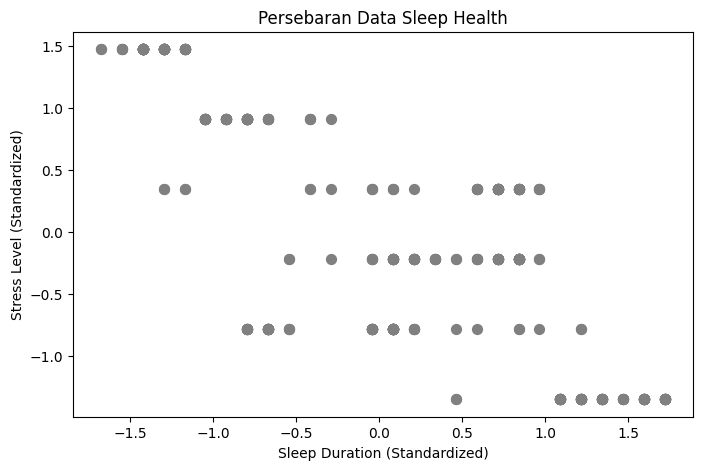

In [ ]:
# Visualisasi Persebaran Data Awal
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], s=50, c='gray')
plt.title('Persebaran Data Sleep Health')
plt.xlabel('Sleep Duration (Standardized)')
plt.ylabel('Stress Level (Standardized)')
plt.show()

In [ ]:
# Penentuan Jumlah Cluster (k) Terbaik dengan Metode Elbow
sse = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    sse.append(kmeans.inertia_)

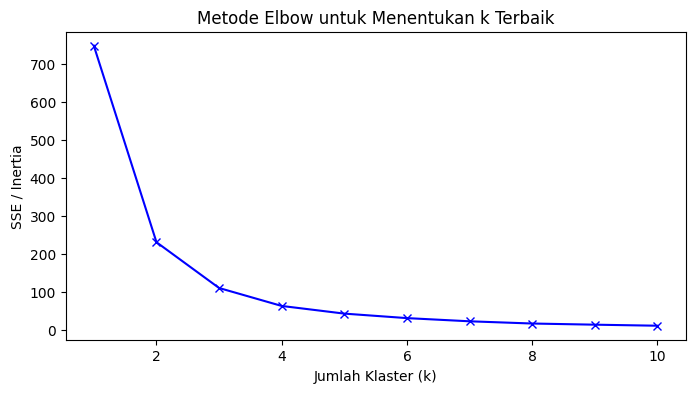

In [ ]:
# Plot Metode Elbow
plt.figure(figsize=(8, 4))
plt.plot(K, sse, 'bx-')
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('SSE / Inertia')
plt.title('Metode Elbow untuk Menentukan k Terbaik')
plt.show()

In [ ]:
# Konfirmasi dengan Silhouette Score
best_k = 2
best_score = -1

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)
    score = silhouette_score(X, labels)
    print(f'k = {k}, Silhouette Score = {score:.4f}')
    if score > best_score:
        best_score = score
        best_k = k

print(f'\nJumlah k optimum berdasarkan Silhouette Score: k = {best_k} ({best_score:.4f})')

k = 2, Silhouette Score = 0.6186
k = 3, Silhouette Score = 0.6242
k = 4, Silhouette Score = 0.6428
k = 5, Silhouette Score = 0.6519
k = 6, Silhouette Score = 0.6577
k = 7, Silhouette Score = 0.6896
k = 8, Silhouette Score = 0.7282
k = 9, Silhouette Score = 0.7100
k = 10, Silhouette Score = 0.7274

Jumlah k optimum berdasarkan Silhouette Score: k = 8 (0.7282)


In [ ]:
# Membuat Model K-Means dengan k Optimum secara otomatis
k_optimum = best_k
kmeans = KMeans(n_clusters=k_optimum, random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X)

/tmp/ipykernel_5788/2312868676.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab10', k_optimum)


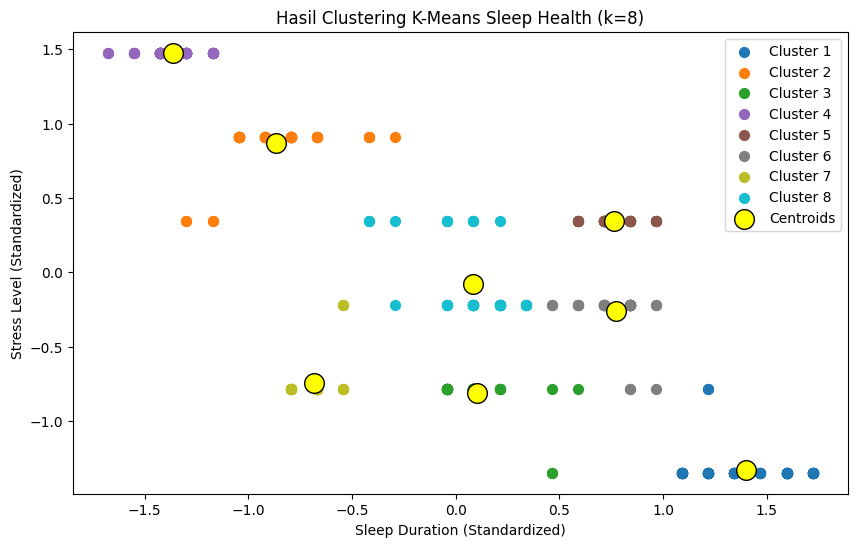

In [ ]:
# Visualisasi Hasil Clustering dan Centroid
plt.figure(figsize=(10, 6))
cmap = plt.cm.get_cmap('tab10', k_optimum)

for i in range(k_optimum):
    plt.scatter(X[y_kmeans == i, 0], X[y_kmeans == i, 1], s=50, color=cmap(i), label=f'Cluster {i+1}')

# Plot Centroid
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], s=200, c='yellow', edgecolors='black', label='Centroids')

plt.title(f'Hasil Clustering K-Means Sleep Health (k={k_optimum})')
plt.xlabel('Sleep Duration (Standardized)')
plt.ylabel('Stress Level (Standardized)')
plt.legend()
plt.show()

## **2. Tugas DBSCAN**
1. Gunakan dataset 'Sleep_health_and_lifestyle_dataset.csv' pada fitur numerik, lalu lakukan standarisasi.
2. Jalankan DBSCAN dengan eps=0.5, min_samples=5, hitung jumlah klaster & noise.
3. Evaluasi dengan metrik: Homogeneity, Completeness, V-measure, ARI, AMI, Silhouette.
4. Visualisasikan hasil DBSCAN (core sample = titik besar, non-core = titik kecil, noise = hitam).
5. Lakukan eksperimen:
    - eps = 0.5, 1.0, 1.5, 2.0
    - min_samples = 3, 5, 10
    - Catat perubahan klaster, noise, dan kualitas evaluasi.



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import DBSCAN
from sklearn import metrics

In [ ]:
# Load dataset Sleep Health & Standarisasi
df_db = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')
fitur_db = ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps']

X = StandardScaler().fit_transform(df_db[fitur_db])

# Encode label asli 'Sleep Disorder' untuk perhitungan metrik evaluasi eksternal
le = LabelEncoder()
y_true = le.fit_transform(df_db['Sleep Disorder'].fillna('None'))

In [ ]:
# Jalankan DBSCAN Baseline (eps=0.5, min_samples=5 disesuaikan untuk 7 dimensi fitur)
db_base = DBSCAN(eps=0.5, min_samples=5).fit(X)
labels_base = db_base.labels_

n_clusters_base = len(set(labels_base)) - (1 if -1 in labels_base else 0)
n_noise_base = list(labels_base).count(-1)

print("--- DBSCAN Baseline (eps=0.5, min_samples=5) ---")
print(f"Jumlah Klaster : {n_clusters_base}")
print(f"Jumlah Noise   : {n_noise_base}\n")

--- DBSCAN Baseline (eps=0.5, min_samples=5) ---
Jumlah Klaster : 13
Jumlah Noise   : 59



In [ ]:
# Evaluasi Metrik untuk Baseline
print("--- Metrik Evaluasi Baseline ---")
print(f"Homogeneity                  : {metrics.homogeneity_score(y_true, labels_base):.3f}")
print(f"Completeness                 : {metrics.completeness_score(y_true, labels_base):.3f}")
print(f"V-measure                    : {metrics.v_measure_score(y_true, labels_base):.3f}")
print(f"Adjusted Rand Index (ARI)    : {metrics.adjusted_rand_score(y_true, labels_base):.3f}")
print(f"Adjusted Mutual Info (AMI)   : {metrics.adjusted_mutual_info_score(y_true, labels_base):.3f}")
if n_clusters_base > 1:
    print(f"Silhouette Coefficient       : {metrics.silhouette_score(X, labels_base):.3f}\n")
else:
    print("Silhouette Coefficient       : N/A (klaster kurang dari 2)\n")

--- Metrik Evaluasi Baseline ---
Homogeneity                  : 0.596
Completeness                 : 0.230
V-measure                    : 0.332
Adjusted Rand Index (ARI)    : 0.120
Adjusted Mutual Info (AMI)   : 0.318
Silhouette Coefficient       : 0.689



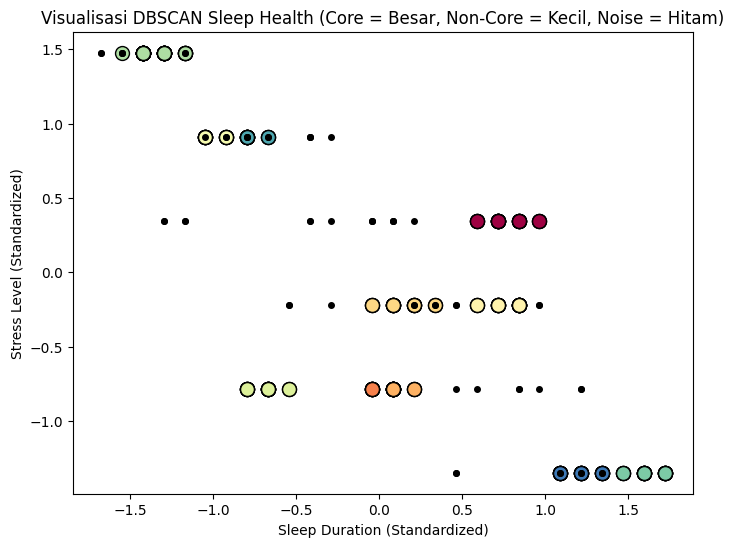

In [ ]:
# Visualisasi Hasil DBSCAN Baseline (menggunakan 2 fitur utama: Sleep Duration & Stress Level)
unique_labels = set(labels_base)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

plt.figure(figsize=(8, 6))
core_samples_mask = np.zeros_like(labels_base, dtype=bool)
core_samples_mask[db_base.core_sample_indices_] = True

for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]  # Noise berwarna hitam

    class_member_mask = (labels_base == k)

    # Core sample (titik besar) - indeks 1 (Sleep Duration) dan indeks 4 (Stress Level)
    xy = X[class_member_mask & core_samples_mask]
    plt.plot(xy[:, 1], xy[:, 4], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=10)

    # Non-core sample (titik kecil)
    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(xy[:, 1], xy[:, 4], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=4)

plt.title('Visualisasi DBSCAN Sleep Health (Core = Besar, Non-Core = Kecil, Noise = Hitam)')
plt.xlabel('Sleep Duration (Standardized)')
plt.ylabel('Stress Level (Standardized)')
plt.show()

In [ ]:
# Eksperimen Variasi Parameter eps dan min_samples
# Nilai eps diperbesar karena data memiliki 7 dimensi fitur (jarak Euclidean lebih lebar dibanding 2D)
eps_values = [0.5, 1.0, 1.5, 2.0]
min_samples_values = [3, 5, 10]

results = []

for eps in eps_values:
    for ms in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=ms).fit(X)
        lbls = db.labels_

        n_clusters = len(set(lbls)) - (1 if -1 in lbls else 0)
        n_noise = list(lbls).count(-1)

        if n_clusters > 1 and len(set(lbls)) > 1:
            sil = metrics.silhouette_score(X, lbls)
            ari = metrics.adjusted_rand_score(y_true, lbls)
            v_meas = metrics.v_measure_score(y_true, lbls)
        else:
            sil, ari, v_meas = np.nan, np.nan, np.nan

        results.append({
            'eps': eps,
            'min_samples': ms,
            'Jumlah Klaster': n_clusters,
            'Jumlah Noise': n_noise,
            'ARI': round(ari, 3) if not np.isnan(ari) else 'N/A',
            'V-Measure': round(v_meas, 3) if not np.isnan(v_meas) else 'N/A',
            'Silhouette': round(sil, 3) if not np.isnan(sil) else 'N/A'
        })

df_results = pd.DataFrame(results)
display(df_results)

,eps,min_samples,Jumlah Klaster,Jumlah Noise,ARI,V-Measure,Silhouette
0,0.5,3,14,56,0.122,0.333,0.698
1,0.5,5,13,59,0.120,0.332,0.689
2,0.5,10,10,77,0.117,0.325,0.620
3,1.0,3,16,35,0.159,0.349,0.716
4,1.0,5,12,49,0.154,0.347,0.687
5,1.0,10,9,68,0.150,0.343,0.625
6,1.5,3,8,10,0.323,0.364,0.302
7,1.5,5,6,17,0.322,0.359,0.300
8,1.5,10,5,23,0.321,0.356,0.324
9,2.0,3,5,6,0.236,0.325,0.377
